# Hybrid AI — Physics-Informed PDE Modeling

**Problem:** Learn the mapping $f(x,y) \mapsto u(x,y)$ for the 2D Poisson equation:
$$-\left(\frac{\partial^2 u}{\partial x^2} + \frac{\partial^2 u}{\partial y^2}\right) = f(x,y) \quad \text{on } \Omega=[0,1]^2$$
with homogeneous Dirichlet boundary conditions $u=0$ on $\partial\Omega$.

**Outline:**
1. Import & Setup
2. Dataset exploration
3. Dataset formatting
4. Utility fonctions
5. Baseline MLP
6. Baseline CNN
7. Comparison & analysis between Baselines
8. Discussion
9. Physics informed neural network
10. Evaluation an comparison on Private Test Set

## 1. Imports & Setup

In [316]:
import os
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, ParameterGrid
import torch
from torch.utils.data import Dataset, DataLoader
import torch.nn as nn
import torch.nn.functional as F
from tqdm import tqdm

RANDOM_SEED = 30

torch.manual_seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cpu


## 2. Dataset Exploration

In [317]:
source = np.load("./training/source.npy")
u_full = np.load("./training/u_full.npy")
x_grid = np.load("./training/x_grid.npy")
y_grid = np.load("./training/y_grid.npy")

print("======= Shapes =======")
print("Source (f):  ", source.shape)
print("Solution (u):", u_full.shape)
print("X Grid:      ", x_grid.shape)
print("Y Grid:      ", y_grid.shape)

======= Shapes =======
Source (f):   (800, 45, 45, 1)
Solution (u): (800, 45, 45, 1)
X Grid:       (45,)
Y Grid:       (45,)


In [318]:
print("Source f :")
print(f"  min = {source.min():.4f}, max = {source.max():.4f}, mean = {source.mean():.4f}")
print("Solution u :")
print(f"  min = {u_full.min():.4f}, max = {u_full.max():.4f}, mean = {u_full.mean():.4f}")

Source f :
  min = -1.9904, max = 1.9973, mean = 0.1707
Solution u :
  min = -0.0287, max = 0.0663, mean = 0.0053


The dataset contains **800 samples** on a **45×45** uniform grid on $[0,1]^2$.
Each sample is generated with a different pair of parameters $(a, b)$ in
$f(x,y) = x\sin(a\pi y) + y\sin(b\pi x)$.

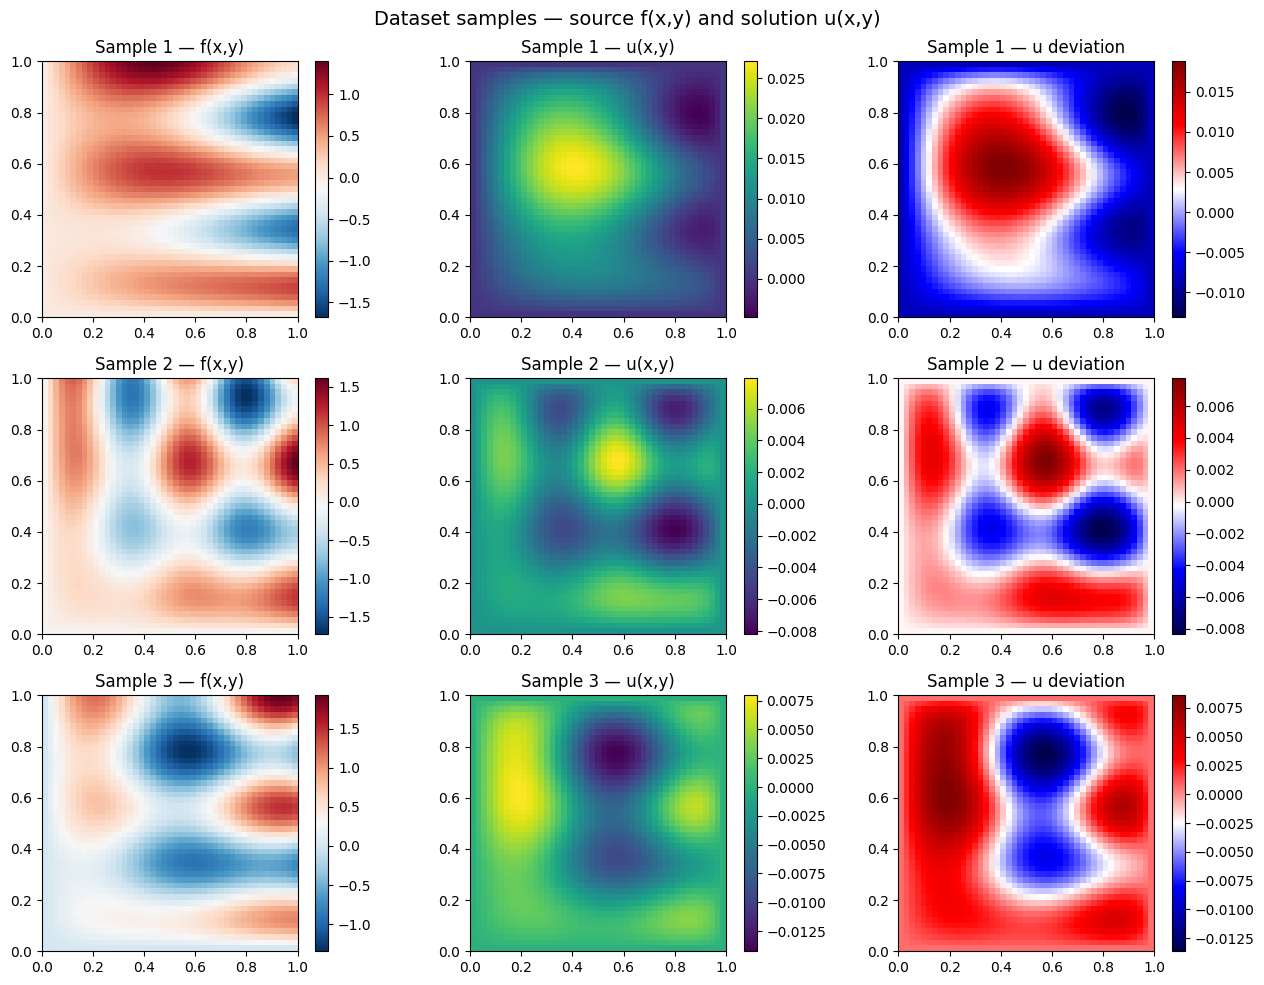

In [319]:
fig, axes = plt.subplots(3, 3, figsize=(13, 10))
fig.suptitle("Dataset samples — source f(x,y) and solution u(x,y)", fontsize=14)

for i in range(3):
    im0 = axes[i, 0].imshow(source[i], cmap='RdBu_r', origin='lower',
                             extent=[0,1,0,1])
    axes[i, 0].set_title(f"Sample {i+1} — f(x,y)")
    plt.colorbar(im0, ax=axes[i, 0])

    im1 = axes[i, 1].imshow(u_full[i], cmap='viridis', origin='lower',
                             extent=[0,1,0,1])
    axes[i, 1].set_title(f"Sample {i+1} — u(x,y)")
    plt.colorbar(im1, ax=axes[i, 1])

    err = u_full[i] - u_full[i].mean()
    im2 = axes[i, 2].imshow(err, cmap='seismic', origin='lower',
                             extent=[0,1,0,1])
    axes[i, 2].set_title(f"Sample {i+1} — u deviation")
    plt.colorbar(im2, ax=axes[i, 2])

plt.tight_layout()
plt.show()

**Observations:**
- The solution $u$ is smooth and satisfies $u=0$ on the boundary (Dirichlet BC).
- The source $f$ varies significantly across samples.
- Both fields are spatially structured → CNNs should have an advantage over flat MLPs.

## 3. Dataset Formatting

In [320]:
class PoissonDataset(Dataset):
    """
    Dataset for the 2D Poisson problem.

    Returns:
        x : FloatTensor of shape (45, 45)  — source field f
        y : FloatTensor of shape (1, 45, 45) — solution field u (NCHW)

    Each model is responsible for reshaping x in its forward() method:
        - MLP  : x.view(-1, 2025)     (flatten)
        - CNN  : x.unsqueeze(1)       (add channel dim)
    """
    def __init__(self, X, y, normalize=False):
        self.normalize = normalize
        # Compute statistics once over the whole split (not per sample)
        if normalize:
            self.xmin, self.xmax = X.min(), X.max()
            self.ymin, self.ymax = y.min(), y.max()
        self.X = X
        self.y = y

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        x = self.X[idx].copy().astype(np.float32)
        y = self.y[idx].copy().astype(np.float32)
        if self.normalize:
            x = 2 * (x - self.xmin) / (self.xmax - self.xmin) - 1
            y = 2 * (y - self.ymin) / (self.ymax - self.ymin) - 1
        x = torch.from_numpy(x).squeeze()        # (45, 45) garanti
        y = torch.from_numpy(y).squeeze().unsqueeze(0)  # (1, 45, 45)
        return x, y

In [321]:
# 85% train+val / 15% test  (random_state fixed for reproducibility)
X_train_val, X_test, y_train_val, y_test = train_test_split(
    source, u_full, test_size=0.15, random_state=RANDOM_SEED
)
# 80% train / 20% val
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.2, random_state=RANDOM_SEED
)

print(f"Train:      {len(X_train)} samples")
print(f"Validation: {len(X_val)} samples")
print(f"Test:       {len(X_test)} samples")

train_dataset = PoissonDataset(X_train, y_train, normalize=False)
val_dataset   = PoissonDataset(X_val,   y_val,   normalize=False)
test_dataset  = PoissonDataset(X_test,  y_test,  normalize=False)

# Verify shapes
x_sample, y_sample = train_dataset[0]
print(f"\nSample x shape: {x_sample.shape}  (input to model)")
print(f"Sample y shape: {y_sample.shape}  (target, NCHW)")

Train:      544 samples
Validation: 136 samples
Test:       120 samples

Sample x shape: torch.Size([45, 45])  (input to model)
Sample y shape: torch.Size([1, 45, 45])  (target, NCHW)


## 4. Utility Functions

In [322]:
def train_model(model, train_loader, val_loader, criterion, optimizer,
                device, num_epochs=100, print_progress=True, save_path=None):
    """
    Train a model and return the loss history.
    Saves the best checkpoint (lowest val loss) to save_path.
    """
    if save_path is None:
        save_path = f"best_{model.__class__.__name__}.pth"

    best_val_loss = float('inf')
    history = {'train_loss': [], 'val_loss': []}

    for epoch in range(num_epochs):
        # --- Training ---
        model.train()
        train_loss = 0.0
        for x_batch, y_batch in train_loader:
            x_batch, y_batch = x_batch.to(device), y_batch.to(device)
            optimizer.zero_grad()
            loss = criterion(model(x_batch), y_batch)
            loss.backward()
            optimizer.step()
            train_loss += loss.item()

        # --- Validation ---
        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for x_batch, y_batch in val_loader:
                x_batch, y_batch = x_batch.to(device), y_batch.to(device)
                val_loss += criterion(model(x_batch), y_batch).item()

        train_loss /= len(train_loader)
        val_loss   /= len(val_loader)
        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)

        if print_progress:
            print(f"Epoch {epoch+1:3d}/{num_epochs} | "
                  f"Train: {train_loss:.6f} | Val: {val_loss:.6f}")

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            torch.save(model.state_dict(), save_path)
            if print_progress:
                print(f"  ✓ Best model saved (val_loss={best_val_loss:.6f})")

    return history

In [323]:
def tune_hyperparameters(X_train, y_train, X_val, y_val,
                         param_grid, device, model_class, model_kwargs=None):
    """
    Grid-search over param_grid. Re-instantiates the model for each combination.

    param_grid must contain: 'lr', 'batch_size', 'num_epochs'.
    model_kwargs may contain architecture hyperparameters (e.g. 'hidden_sizes');
    those present in param_grid will be overridden per combination.
    """
    if model_kwargs is None:
        model_kwargs = {}

    best_score   = float('inf')
    best_params  = None
    best_history = None

    for params in tqdm(list(ParameterGrid(param_grid)),
                       desc="Hyperparameter Tuning", unit="combination"):
        # Merge fixed kwargs with current grid params (grid overrides fixed)
        kwargs = {**model_kwargs,
                  **{k: v for k, v in params.items()
                     if k not in ('lr', 'batch_size', 'num_epochs')}}

        current_model = model_class(**kwargs).to(device)

        train_ds = PoissonDataset(X_train, y_train, normalize=False)
        val_ds   = PoissonDataset(X_val,   y_val,   normalize=False)
        train_loader = DataLoader(train_ds, batch_size=params['batch_size'], shuffle=True)
        val_loader   = DataLoader(val_ds,   batch_size=params['batch_size'], shuffle=False)

        optimizer = torch.optim.Adam(current_model.parameters(), lr=params['lr'])
        criterion = nn.MSELoss()

        history = train_model(
            current_model, train_loader, val_loader, criterion, optimizer,
            device, num_epochs=params['num_epochs'], print_progress=False
        )

        # Compare on best val loss (not last epoch)
        score = min(history['val_loss'])
        if score < best_score:
            best_score   = score
            best_params  = params
            best_history = history

    print(f"\nBest val loss: {best_score:.6f}")
    return best_params, best_history

In [324]:
def evaluate_model(model, loader, device):
    """Return MSE and MAE on a DataLoader."""
    model.eval()
    mse_total, mae_total, n = 0.0, 0.0, 0
    with torch.no_grad():
        for x_batch, y_batch in loader:
            x_batch, y_batch = x_batch.to(device), y_batch.to(device)
            pred = model(x_batch)
            mse_total += F.mse_loss(pred, y_batch, reduction='sum').item()
            mae_total += F.l1_loss(pred,  y_batch, reduction='sum').item()
            n += y_batch.numel()
    return mse_total / n, mae_total / n


def plot_loss(history, title="", save_path=None):
    plt.figure(figsize=(9, 4))
    plt.plot(history['train_loss'], label='Train Loss')
    plt.plot(history['val_loss'],   label='Val Loss')
    plt.xlabel('Epoch')
    plt.ylabel('MSE Loss')
    plt.title(title)
    plt.legend()
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=120)
    plt.show()


def denormalize(x, min_val, max_val):
    return (x + 1) * (max_val - min_val) / 2 + min_val

def plot_comparison(model, X, y, idx=0, title="", save_path=None):
    """Visualise input / prediction / ground truth / absolute error."""
    model.eval()
    with torch.no_grad():
        x_t = torch.FloatTensor(X[idx:idx+1]).to(device)
        x_t = x_t.squeeze(dim=-1)
        pred = model(x_t).cpu().numpy().squeeze()   # (45, 45)
    true = y[idx].squeeze()                          # (45, 45)
    error = np.abs(pred - true)

    fig, axes = plt.subplots(1, 4, figsize=(16, 4))
    fig.suptitle(title, fontsize=13)

    kw = dict(origin='lower', extent=[0,1,0,1])
    im0 = axes[0].imshow(X[idx].squeeze(), cmap='RdBu_r', **kw)
    axes[0].set_title("Input f(x,y)")
    plt.colorbar(im0, ax=axes[0])

    im1 = axes[1].imshow(pred, cmap='viridis', **kw)
    axes[1].set_title("Predicted u")
    plt.colorbar(im1, ax=axes[1])

    im2 = axes[2].imshow(true, cmap='viridis', **kw)
    axes[2].set_title("True u")
    plt.colorbar(im2, ax=axes[2])

    im3 = axes[3].imshow(error, cmap='hot', **kw)
    axes[3].set_title("Absolute error")
    plt.colorbar(im3, ax=axes[3])

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=120)
    plt.show()

## 5. Baseline 1 — MLP

A fully connected network that **ignores spatial structure**: the 45×45 grid is flattened to a vector of size 2025, and the output is also a flat vector reshaped back to (1, 45, 45).

This model can in principle approximate any function (universal approximation theorem) but has no notion of locality or translation equivariance.

In [325]:
class MLP(nn.Module):
    """
    MLP: (N, 45, 45) → flatten → FC layers → (N, 1, 45, 45)
    """
    def __init__(self, input_size=2025, hidden_sizes=[512, 256], output_size=2025):
        super().__init__()
        layers = []
        in_dim = input_size
        for h in hidden_sizes:
            layers += [nn.Linear(in_dim, h), nn.ReLU()]
            in_dim = h
        layers.append(nn.Linear(in_dim, output_size))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        # x : (N, 45, 45)
        x = x.view(x.size(0), -1)      # → (N, 2025)
        x = self.net(x)                 # → (N, 2025)
        return x.view(x.size(0), 1, 45, 45)  # → (N, 1, 45, 45)

In [326]:
mlp_param_grid = {
    'hidden_sizes': [[512, 256], [1024, 512]],
    'lr':           [1e-3, 1e-4],
    'batch_size':   [16, 32],
    'num_epochs':   [5, 10],
}

best_mlp_params, best_mlp_history = tune_hyperparameters(
    X_train, y_train, X_val, y_val,
    param_grid=mlp_param_grid,
    device=device,
    model_class=MLP,
    model_kwargs={'input_size': 2025, 'output_size': 2025},
)

print("Best MLP hyperparameters:", best_mlp_params)

Hyperparameter Tuning: 100%|██████████| 16/16 [00:54<00:00,  3.42s/combination]


Best val loss: 0.000009
Best MLP hyperparameters: {'batch_size': 16, 'hidden_sizes': [1024, 512], 'lr': 0.0001, 'num_epochs': 10}


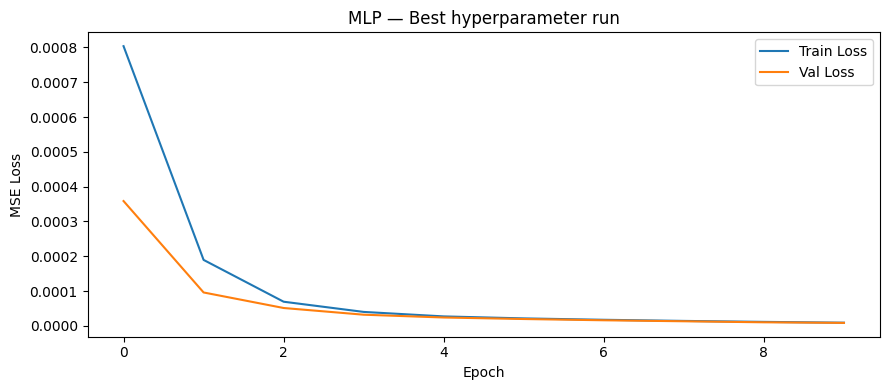

In [327]:
plot_loss(best_mlp_history, title="MLP — Best hyperparameter run",
          save_path=None)

In [328]:
# Re-train from scratch with best params to get the saved checkpoint
best_mlp = MLP(
    input_size=2025,
    hidden_sizes=best_mlp_params['hidden_sizes'],
    output_size=2025
).to(device)

mlp_train_loader = DataLoader(
    PoissonDataset(X_train, y_train), batch_size=best_mlp_params['batch_size'], shuffle=True)
mlp_val_loader = DataLoader(
    PoissonDataset(X_val, y_val),     batch_size=best_mlp_params['batch_size'], shuffle=False)

mlp_history = train_model(
    best_mlp, mlp_train_loader, mlp_val_loader,
    criterion=nn.MSELoss(),
    optimizer=torch.optim.Adam(best_mlp.parameters(), lr=best_mlp_params['lr']),
    device=device,
    num_epochs=best_mlp_params['num_epochs'],
    print_progress=True,
    save_path="best_MLP.pth"
)

Epoch   1/10 | Train: 0.000809 | Val: 0.000361
  ✓ Best model saved (val_loss=0.000361)
Epoch   2/10 | Train: 0.000199 | Val: 0.000102
  ✓ Best model saved (val_loss=0.000102)
Epoch   3/10 | Train: 0.000071 | Val: 0.000051
  ✓ Best model saved (val_loss=0.000051)
Epoch   4/10 | Train: 0.000039 | Val: 0.000032
  ✓ Best model saved (val_loss=0.000032)
Epoch   5/10 | Train: 0.000027 | Val: 0.000025
  ✓ Best model saved (val_loss=0.000025)
Epoch   6/10 | Train: 0.000023 | Val: 0.000022
  ✓ Best model saved (val_loss=0.000022)
Epoch   7/10 | Train: 0.000020 | Val: 0.000019
  ✓ Best model saved (val_loss=0.000019)
Epoch   8/10 | Train: 0.000018 | Val: 0.000017
  ✓ Best model saved (val_loss=0.000017)
Epoch   9/10 | Train: 0.000015 | Val: 0.000014
  ✓ Best model saved (val_loss=0.000014)
Epoch  10/10 | Train: 0.000013 | Val: 0.000012
  ✓ Best model saved (val_loss=0.000012)


In [329]:
# Load best checkpoint and evaluate on test set
best_mlp.load_state_dict(torch.load("best_MLP.pth", map_location=device))

test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)
mlp_test_mse, mlp_test_mae = evaluate_model(best_mlp, test_loader, device)
print(f"MLP — Test MSE: {mlp_test_mse:.6f} | Test MAE: {mlp_test_mae:.6f}")

MLP — Test MSE: 0.000012 | Test MAE: 0.002703


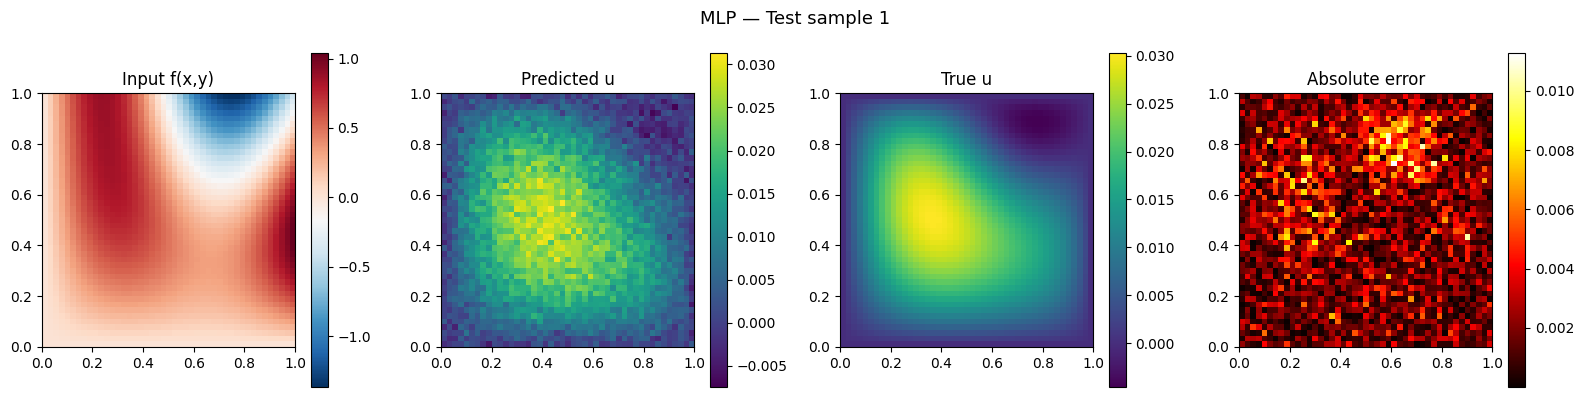

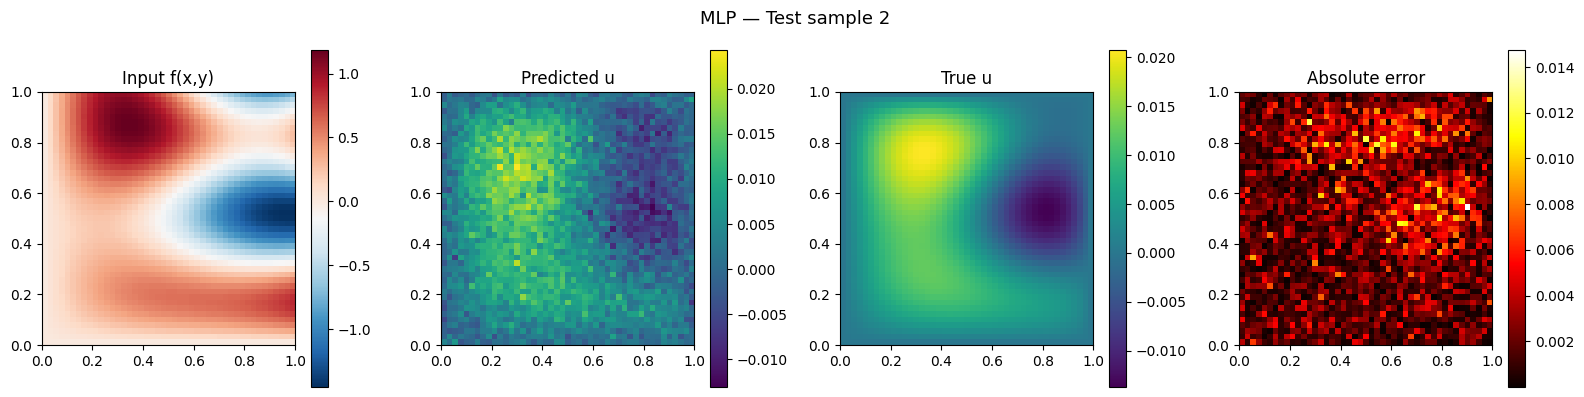

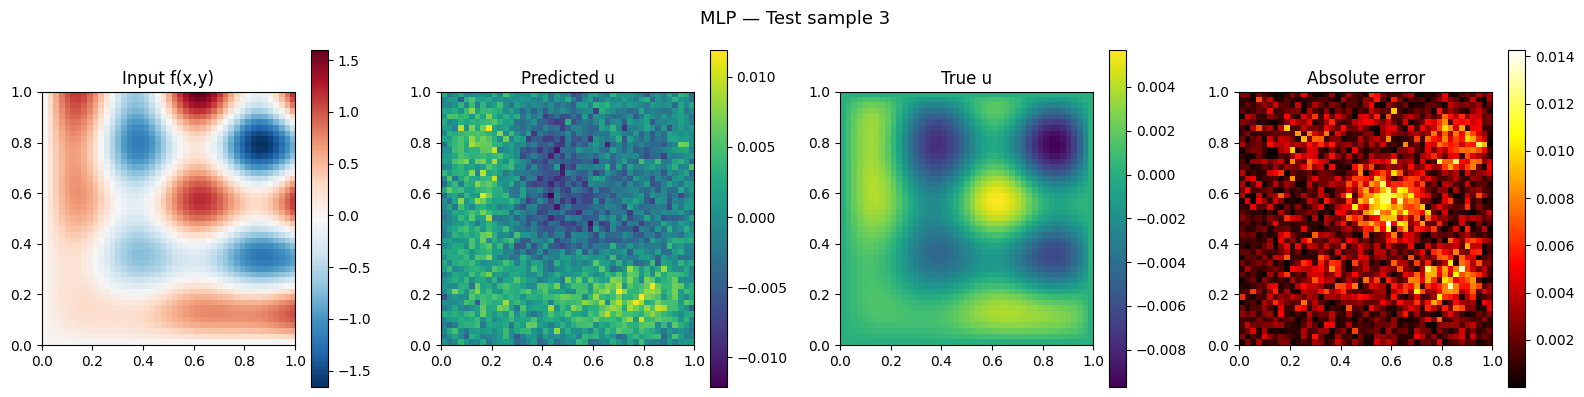

In [330]:
for idx in range(3):
    plot_comparison(best_mlp, X_test, y_test, idx=idx,
                    title=f"MLP — Test sample {idx+1}",
                    save_path=f"mlp_comparison_{idx}_{RANDOM_SEED}.png")

### MLP — Observations

- The MLP has no spatial awareness: it treats every input pixel independently.
- Predictions may lack smoothness and could violate boundary conditions.
- The large number of parameters in the first FC layer ($2025 \times H$) makes it heavy despite its apparent simplicity.

## 6. Baseline 2 — CNN

A convolutional network that **exploits the 2D spatial structure** of the problem. Convolutions are local and translation-equivariant, which is a natural inductive bias for grid-based PDE data.

Architecture: two conv+pool blocks followed by a fully connected head.

In [331]:
class SimpleCNN(nn.Module):
    """
    CNN: (N, 45, 45) → unsqueeze → conv blocks → FC → (N, 1, 45, 45)

    Spatial flow:
        (1, 45, 45) → Conv+Pool → (32, 22, 22)
                    → Conv+Pool → (64, 11, 11)
                    → Flatten  → 7744
                    → FC       → 2025
                    → Reshape  → (1, 45, 45)
    """
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1,  32, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.pool  = nn.MaxPool2d(2, 2)
        # 45 → pool → 22 → pool → 11
        self.fc1   = nn.Linear(64 * 11 * 11, 2025)

    def forward(self, x):
        # x : (N, 45, 45)
        x = x.reshape(x.size(0), 1, 45, 45)         # → (N,  1, 45, 45)
        x = self.pool(F.relu(self.conv1(x)))        # → (N, 32, 22, 22)
        x = self.pool(F.relu(self.conv2(x)))        # → (N, 64, 11, 11)
        x = x.view(x.size(0), -1)                   # → (N, 7744)
        x = self.fc1(x)                             # → (N, 2025)
        return x.view(x.size(0), 1, 45, 45)         # → (N, 1, 45, 45)

In [332]:
print(X_train[0].shape, y_train[0].shape)

(45, 45, 1) (45, 45, 1)


In [333]:
cnn_param_grid = {
    'lr':         [1e-3, 5e-4, 1e-4],
    'batch_size': [16, 32],
    'num_epochs': [10, 20],
}



best_cnn_params, best_cnn_history = tune_hyperparameters(
    X_train, y_train, X_val, y_val,
    param_grid=cnn_param_grid,
    device=device,
    model_class=SimpleCNN,
    model_kwargs={},
)

print("Best CNN hyperparameters:", best_cnn_params)

Hyperparameter Tuning: 100%|██████████| 12/12 [08:44<00:00, 43.69s/combination]


Best val loss: 0.000002
Best CNN hyperparameters: {'batch_size': 16, 'lr': 0.0005, 'num_epochs': 20}


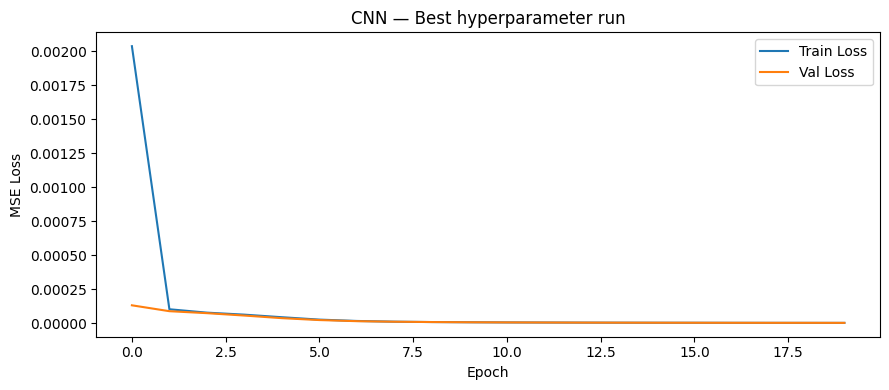

In [334]:
plot_loss(best_cnn_history, title="CNN — Best hyperparameter run",
          save_path=None)

In [335]:
best_cnn = SimpleCNN().to(device)

cnn_train_loader = DataLoader(
    PoissonDataset(X_train, y_train), batch_size=best_cnn_params['batch_size'], shuffle=True)
cnn_val_loader = DataLoader(
    PoissonDataset(X_val, y_val),     batch_size=best_cnn_params['batch_size'], shuffle=False)

cnn_history = train_model(
    best_cnn, cnn_train_loader, cnn_val_loader,
    criterion=nn.MSELoss(),
    optimizer=torch.optim.Adam(best_cnn.parameters(), lr=best_cnn_params['lr']),
    device=device,
    num_epochs=best_cnn_params['num_epochs'],
    print_progress=True,
    save_path="best_SimpleCNN.pth"
)

Epoch   1/20 | Train: 0.002660 | Val: 0.000148
  ✓ Best model saved (val_loss=0.000148)
Epoch   2/20 | Train: 0.000113 | Val: 0.000098
  ✓ Best model saved (val_loss=0.000098)
Epoch   3/20 | Train: 0.000087 | Val: 0.000085
  ✓ Best model saved (val_loss=0.000085)
Epoch   4/20 | Train: 0.000078 | Val: 0.000077
  ✓ Best model saved (val_loss=0.000077)
Epoch   5/20 | Train: 0.000068 | Val: 0.000064
  ✓ Best model saved (val_loss=0.000064)
Epoch   6/20 | Train: 0.000054 | Val: 0.000048
  ✓ Best model saved (val_loss=0.000048)
Epoch   7/20 | Train: 0.000037 | Val: 0.000030
  ✓ Best model saved (val_loss=0.000030)
Epoch   8/20 | Train: 0.000022 | Val: 0.000017
  ✓ Best model saved (val_loss=0.000017)
Epoch   9/20 | Train: 0.000013 | Val: 0.000010
  ✓ Best model saved (val_loss=0.000010)
Epoch  10/20 | Train: 0.000008 | Val: 0.000007
  ✓ Best model saved (val_loss=0.000007)
Epoch  11/20 | Train: 0.000006 | Val: 0.000006
  ✓ Best model saved (val_loss=0.000006)
Epoch  12/20 | Train: 0.000005 |

In [336]:
best_cnn.load_state_dict(torch.load("best_SimpleCNN.pth", map_location=device))

cnn_test_mse, cnn_test_mae = evaluate_model(best_cnn, test_loader, device)
print(f"CNN — Test MSE: {cnn_test_mse:.6f} | Test MAE: {cnn_test_mae:.6f}")

CNN — Test MSE: 0.000002 | Test MAE: 0.001124


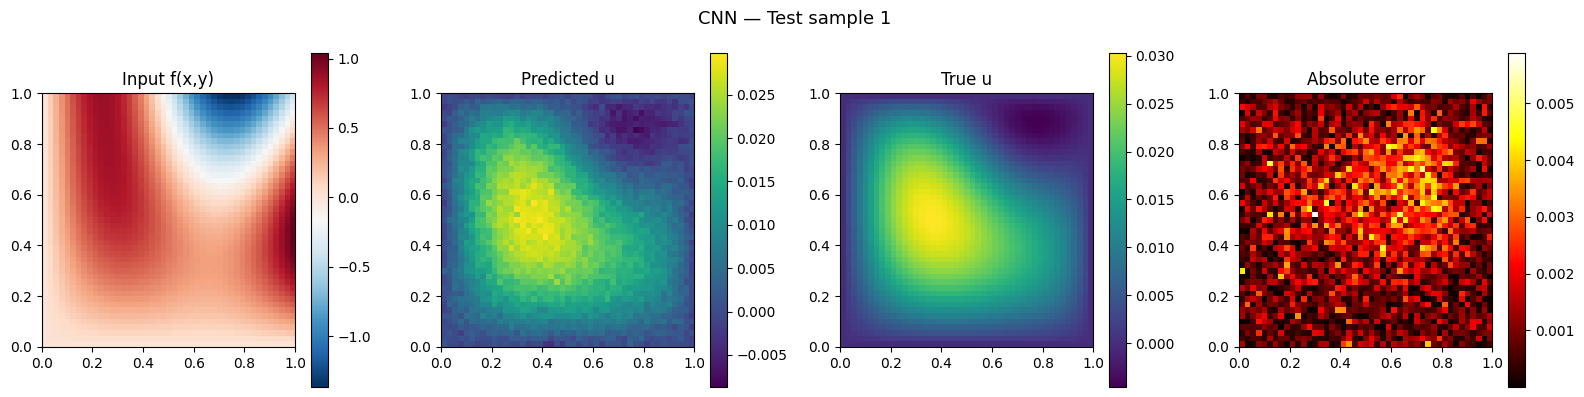

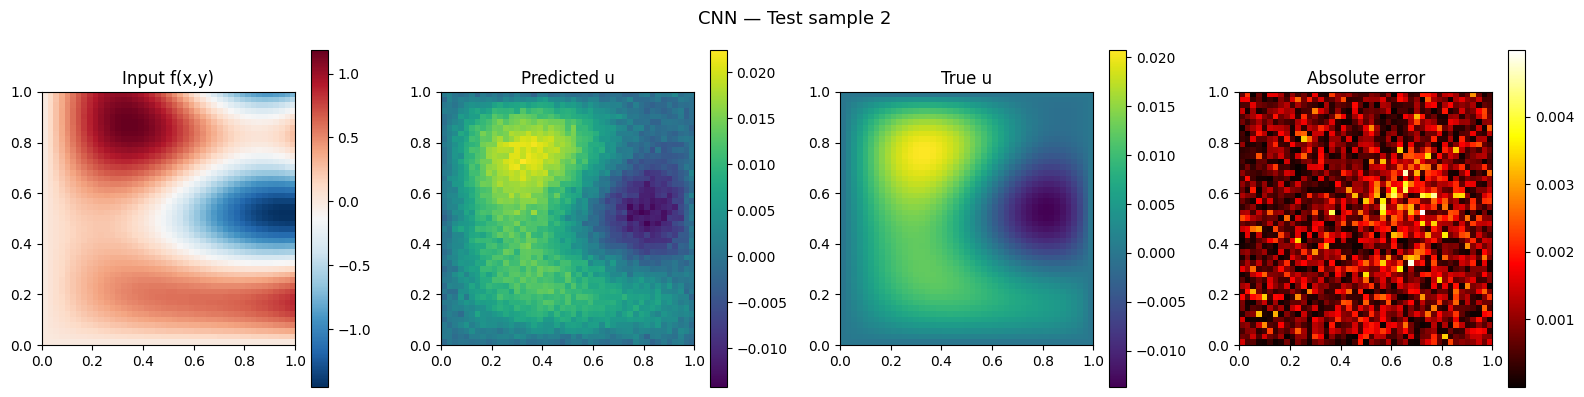

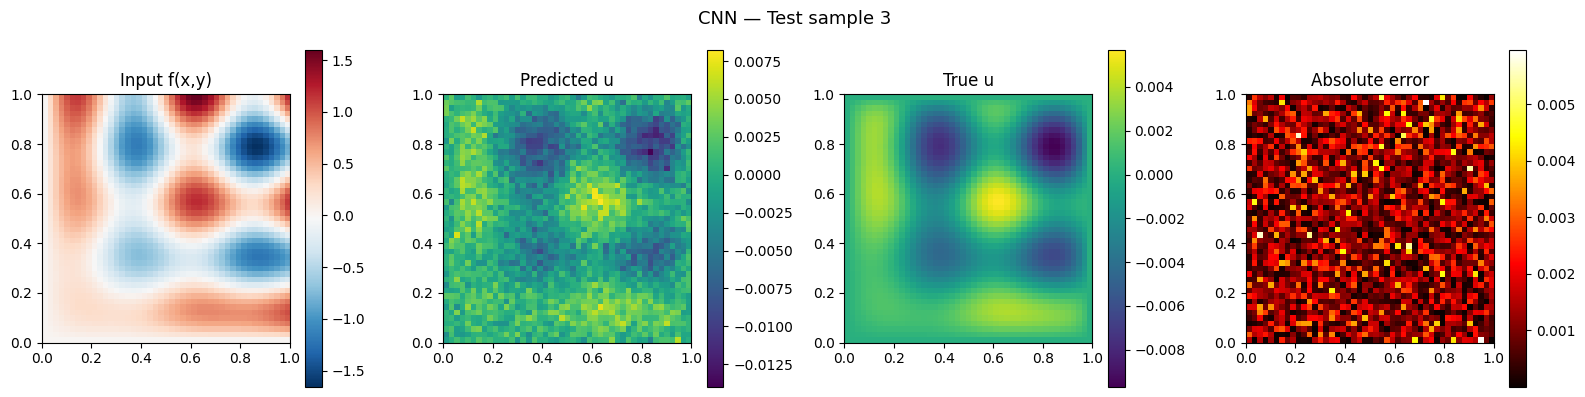

In [337]:
for idx in range(3):
    plot_comparison(best_cnn, X_test, y_test, idx=idx,
                    title=f"CNN — Test sample {idx+1}",
                    save_path=f"cnn_comparison_{idx}_{RANDOM_SEED}.png")

### CNN — Observations

- Convolutions naturally encode locality: the solution at a point depends primarily on nearby values of $f$.
- MaxPooling loses resolution, which may harm reconstruction quality; a U-Net-style architecture would address this.
- Predictions are typically smoother than MLP outputs.

## 7. Comparison MLP vs CNN

In [338]:
# --- Parameter count ---
def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"MLP parameters : {count_params(best_mlp):,}")
print(f"CNN parameters : {count_params(best_cnn):,}")

# --- Metrics summary ---
print(f"\n{'Model':<8} {'Test MSE':>12} {'Test MAE':>12}")
print("-" * 34)
print(f"{'MLP':<8} {mlp_test_mse:>12.6f} {mlp_test_mae:>12.6f}")
print(f"{'CNN':<8} {cnn_test_mse:>12.6f} {cnn_test_mae:>12.6f}")

MLP parameters : 3,638,249
CNN parameters : 15,702,441

Model        Test MSE     Test MAE
----------------------------------
MLP          0.000012     0.002703
CNN          0.000002     0.001124


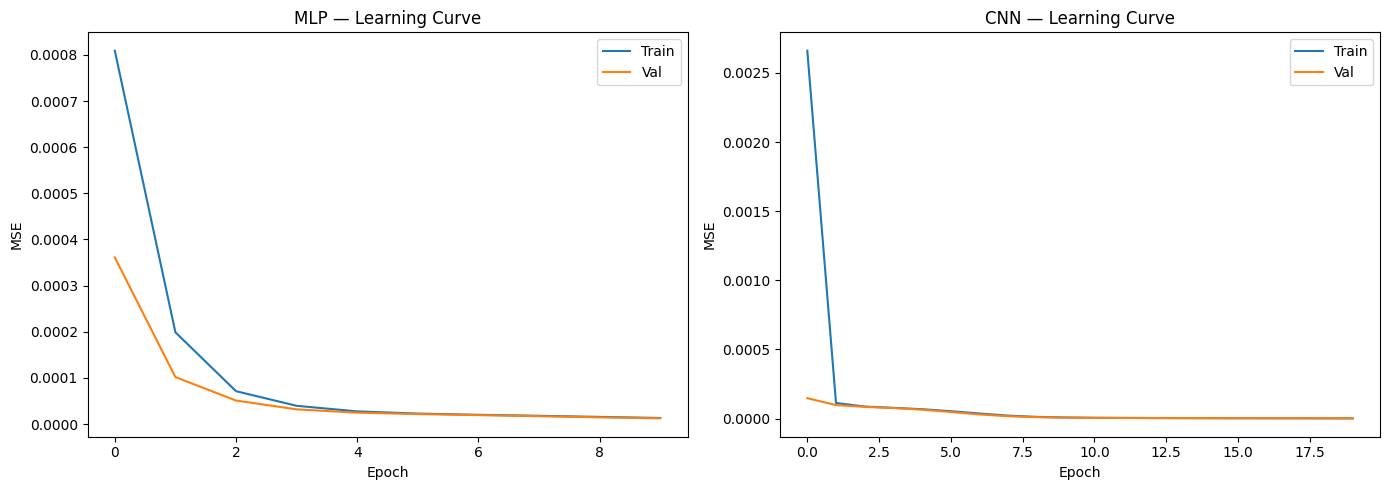

In [339]:
# --- Learning curves side by side ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, history, label in zip(axes,
                               [mlp_history, cnn_history],
                               ["MLP", "CNN"]):
    ax.plot(history['train_loss'], label='Train')
    ax.plot(history['val_loss'],   label='Val')
    ax.set_title(f"{label} — Learning Curve")
    ax.set_xlabel('Epoch')
    ax.set_ylabel('MSE')
    ax.legend()

plt.tight_layout()
plt.show()

## 8. Discussion

### MLP vs CNN

| | MLP | CNN |
|---|---|---|
| Spatial bias | ✗ None | ✓ Local, translation-equivariant |
| # Parameters | High (dense layers) | Fewer (shared kernels) |
| Prediction quality | Smooth? | Generally smoother |
| Boundary conditions | Not enforced | Not enforced |

### Limitations of both baselines

1. **No physics**: neither model knows the Poisson equation. Errors are purely data-driven.
2. **Boundary conditions**: $u=0$ on $\partial\Omega$ is not enforced — the model must learn it from data.
3. **Generalization**: the test set uses a different $(a,b)$ distribution. Models that only memorize patterns may fail to generalize.
4. **CNN resolution loss**: MaxPooling discards spatial information; a U-Net with skip connections would preserve it.

## 9. Physics informed network — CNN-PINN with hybrid loss

The idea is to add 2 physics informed terms in the loss :

$$
\mathcal{L} = \underbrace{\|u_{pred} - u_{true}\|^2}_{\text{data loss}}
            + \lambda_r \underbrace{\|-\Delta u_{pred} - f\|^2}_{\text{residue EDP}}
            + \lambda_{bc} \underbrace{\|u_{pred}|_{\partial\Omega}\|^2}_{\text{BC loss}}
$$

**Discrete Laplacian** on an uniform grid with a step of $h = 1/(N-1)$ :

$$
\Delta u_{i,j} \approx \frac{u_{i+1,j} + u_{i-1,j} + u_{i,j+1} + u_{i,j-1} - 4u_{i,j}}{h^2}
$$

Implemented as a **2D fixed convolutionnal kernel**.

In [340]:

N_GRID = 45
H = 1.0 / (N_GRID - 1)


laplacian_kernel = torch.zeros(1, 1, 3, 3)
laplacian_kernel[0, 0, 1, 1] = -4.0
laplacian_kernel[0, 0, 0, 1] =  1.0
laplacian_kernel[0, 0, 2, 1] =  1.0
laplacian_kernel[0, 0, 1, 0] =  1.0
laplacian_kernel[0, 0, 1, 2] =  1.0
laplacian_kernel = laplacian_kernel / (H ** 2)
laplacian_kernel = laplacian_kernel.to(device)
print(f"Laplacian kernel (without 1/h^2) :\n{laplacian_kernel.squeeze() * H**2}")
print(f"h = {H:.5f},  1/h^2 = {1/H**2:.2f}")

Laplacian kernel (without 1/h^2) :
tensor([[ 0.,  1.,  0.],
        [ 1., -4.,  1.],
        [ 0.,  1.,  0.]])
h = 0.02273,  1/h^2 = 1936.00


In [341]:
def pde_residual_loss(u_pred, f_batch, laplacian_kernel):
    lap_u = F.conv2d(u_pred, laplacian_kernel, padding=1)   # (N, 1, 45, 45)
    f = f_batch.unsqueeze(1)                                 # (N, 1, 45, 45)
    residual = -lap_u[:, :, 1:-1, 1:-1] - f[:, :, 1:-1, 1:-1]
    return (residual ** 2).mean()


def bc_loss(u_pred):
    top    = u_pred[:, :,  0, :]
    bottom = u_pred[:, :, -1, :]
    left   = u_pred[:, :, :,  0]
    right  = u_pred[:, :, :, -1]
    border = torch.cat([top.reshape(-1), bottom.reshape(-1),
                        left.reshape(-1), right.reshape(-1)])
    return (border ** 2).mean()

In [342]:
def train_pinn(model, train_loader, val_loader,
               laplacian_kernel, optimizer, device,
               num_epochs=15, lambda_r=0.1, lambda_bc=0.1,
               print_progress=True, save_path=None):
    if save_path is None:
        save_path = f"best_{model.__class__.__name__}_PINN.pth"

    best_val = float('inf')
    keys = ['train_total','train_data','train_pde','train_bc',
            'val_total',  'val_data',  'val_pde',  'val_bc']
    history = {k: [] for k in keys}

    for epoch in range(num_epochs):
        # -- Train
        model.train()
        t = {'total':0.,'data':0.,'pde':0.,'bc':0.}
        for x_batch, y_batch in train_loader:
            x_batch, y_batch = x_batch.to(device), y_batch.to(device)
            optimizer.zero_grad()
            pred   = model(x_batch)
            l_data = F.mse_loss(pred, y_batch)
            l_pde  = pde_residual_loss(pred, x_batch, laplacian_kernel)
            l_bc   = bc_loss(pred)
            loss   = l_data + lambda_r * l_pde + lambda_bc * l_bc
            loss.backward()
            optimizer.step()
            t['total'] += loss.item(); t['data'] += l_data.item()
            t['pde']   += l_pde.item(); t['bc']  += l_bc.item()

        # -- Validation
        model.eval()
        v = {'total':0.,'data':0.,'pde':0.,'bc':0.}
        with torch.no_grad():
            for x_batch, y_batch in val_loader:
                x_batch, y_batch = x_batch.to(device), y_batch.to(device)
                pred   = model(x_batch)
                l_data = F.mse_loss(pred, y_batch)
                l_pde  = pde_residual_loss(pred, x_batch, laplacian_kernel)
                l_bc   = bc_loss(pred)
                v['total'] += (l_data + lambda_r*l_pde + lambda_bc*l_bc).item()
                v['data']  += l_data.item()
                v['pde']   += l_pde.item()
                v['bc']    += l_bc.item()

        n_tr, n_vl = len(train_loader), len(val_loader)
        for k in ['total','data','pde','bc']:
            history[f'train_{k}'].append(t[k]/n_tr)
            history[f'val_{k}'].append(v[k]/n_vl)

        if print_progress:
            print(f"Epoch {epoch+1:3d}/{num_epochs}  |  "
                  f"Train {t['total']/n_tr:.5f}  "
                  f"(data={t['data']/n_tr:.5f} "
                  f"pde={t['pde']/n_tr:.5f} "
                  f"bc={t['bc']/n_tr:.5f})  |  "
                  f"Val {v['total']/n_vl:.5f}")

        if history['val_total'][-1] < best_val:
            best_val = history['val_total'][-1]
            torch.save(model.state_dict(), save_path)
            if print_progress:
                print(f"  [saved] val={best_val:.5f}")

    return history

In [343]:
class CNNPinn(nn.Module):
    def __init__(self, base_channels=32):
        super().__init__()
        c = base_channels

        self.enc1 = nn.Sequential(
            nn.Conv2d(1,   c,   3, padding=1), nn.ReLU(),
            nn.Conv2d(c,   c,   3, padding=1), nn.ReLU(),
        )
        self.pool1 = nn.MaxPool2d(2, 2)

        self.enc2 = nn.Sequential(
            nn.Conv2d(c,   c*2, 3, padding=1), nn.ReLU(),
            nn.Conv2d(c*2, c*2, 3, padding=1), nn.ReLU(),
        )
        self.pool2 = nn.MaxPool2d(2, 2)

        self.bottleneck = nn.Sequential(
            nn.Conv2d(c*2, c*4, 3, padding=1), nn.ReLU(),
            nn.Conv2d(c*4, c*2, 3, padding=1), nn.ReLU(),
        )

        # concat skip enc2 : c*2 + c*2 = c*4 canaux en entree
        self.dec2 = nn.Sequential(
            nn.Conv2d(c*4, c*2, 3, padding=1), nn.ReLU(),
            nn.Conv2d(c*2, c,   3, padding=1), nn.ReLU(),
        )

        # concat skip enc1 : c + c = c*2 canaux en entree
        self.dec1 = nn.Sequential(
            nn.Conv2d(c*2, c, 3, padding=1), nn.ReLU(),
            nn.Conv2d(c,   c, 3, padding=1), nn.ReLU(),
        )

        self.out_conv = nn.Conv2d(c, 1, kernel_size=1)

    def forward(self, x):
        x  = x.unsqueeze(1)                                           # (N,1,45,45)
        s1 = self.enc1(x)                                             # (N,c,45,45)
        s2 = self.enc2(self.pool1(s1))                                # (N,2c,22,22)
        b  = self.bottleneck(self.pool2(s2))                          # (N,2c,11,11)
        u2 = F.interpolate(b,  size=s2.shape[2:], mode='bilinear', align_corners=False)
        u2 = self.dec2(torch.cat([u2, s2], dim=1))                    # (N,c,22,22)
        u1 = F.interpolate(u2, size=s1.shape[2:], mode='bilinear', align_corners=False)
        u1 = self.dec1(torch.cat([u1, s1], dim=1))                    # (N,c,45,45)
        return self.out_conv(u1)                                       # (N,1,45,45)
    

### Training

In [344]:
PINN_LR        = 1e-3
PINN_BATCH     = 32
PINN_EPOCHS    = 50
PINN_LAMBDA_R  = 0.1   # poids residue EDP
PINN_LAMBDA_BC = 100   # poids BC

pinn_train_loader = DataLoader(
    PoissonDataset(X_train, y_train, normalize=False), batch_size=PINN_BATCH, shuffle=True)
pinn_val_loader = DataLoader(
    PoissonDataset(X_val, y_val, normalize=False),     batch_size=PINN_BATCH, shuffle=False)

pinn_model     = CNNPinn(base_channels=32).to(device)
pinn_optimizer = torch.optim.Adam(pinn_model.parameters(), lr=PINN_LR)

print(f"CNN-PINN parameters : {count_params(pinn_model):,}")
print(f"lambda_r  = {PINN_LAMBDA_R}")
print(f"lambda_bc = {PINN_LAMBDA_BC}")

CNN-PINN parameters : 332,641
lambda_r  = 0.1
lambda_bc = 100


In [345]:
pinn_history = train_pinn(
    pinn_model, pinn_train_loader, pinn_val_loader,
    laplacian_kernel = laplacian_kernel,
    optimizer        = pinn_optimizer,
    device           = device,
    num_epochs       = PINN_EPOCHS,
    lambda_r         = PINN_LAMBDA_R,
    lambda_bc        = PINN_LAMBDA_BC,
    print_progress   = True,
    save_path        = "best_CNNPinn_PINN.pth"
)

Epoch   1/50  |  Train 1.08121  (data=0.00719 pde=4.32084 bc=0.00642)  |  Val 0.34718
  [saved] val=0.34718
Epoch   2/50  |  Train 0.16945  (data=0.00138 pde=0.57353 bc=0.00111)  |  Val 0.05030
  [saved] val=0.05030
Epoch   3/50  |  Train 0.02813  (data=0.00010 pde=0.24215 bc=0.00004)  |  Val 0.01900
  [saved] val=0.01900
Epoch   4/50  |  Train 0.01482  (data=0.00005 pde=0.13515 bc=0.00001)  |  Val 0.01164
  [saved] val=0.01164
Epoch   5/50  |  Train 0.00936  (data=0.00003 pde=0.08918 bc=0.00000)  |  Val 0.00838
  [saved] val=0.00838
Epoch   6/50  |  Train 0.00717  (data=0.00002 pde=0.06803 bc=0.00000)  |  Val 0.00681
  [saved] val=0.00681
Epoch   7/50  |  Train 0.00568  (data=0.00002 pde=0.05367 bc=0.00000)  |  Val 0.00530
  [saved] val=0.00530
Epoch   8/50  |  Train 0.00459  (data=0.00001 pde=0.04314 bc=0.00000)  |  Val 0.00433
  [saved] val=0.00433
Epoch   9/50  |  Train 0.00384  (data=0.00001 pde=0.03597 bc=0.00000)  |  Val 0.00373
  [saved] val=0.00373
Epoch  10/50  |  Train 0.003

### Loss plot

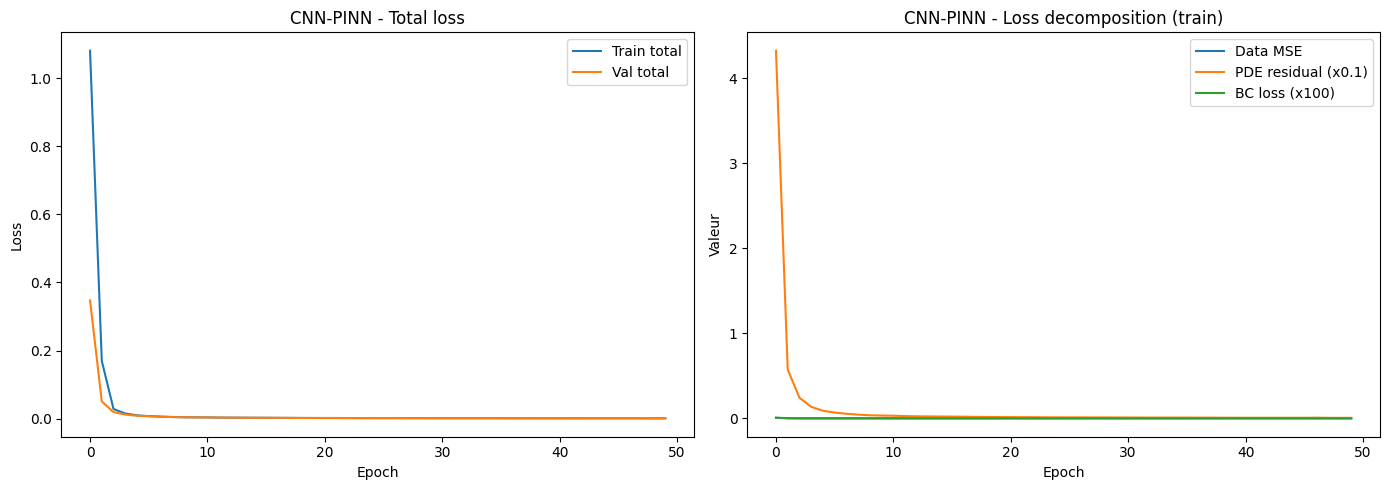

In [346]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(pinn_history['train_total'], label='Train total')
axes[0].plot(pinn_history['val_total'],   label='Val total')
axes[0].set_title('CNN-PINN - Total loss')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss')
axes[0].legend()

axes[1].plot(pinn_history['train_data'], label='Data MSE')
axes[1].plot(pinn_history['train_pde'],  label=f'PDE residual (x{PINN_LAMBDA_R})')
axes[1].plot(pinn_history['train_bc'],   label=f'BC loss (x{PINN_LAMBDA_BC})')
axes[1].set_title('CNN-PINN - Loss decomposition (train)')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Valeur')
axes[1].legend()

plt.tight_layout()
plt.show()

### Evaluation on test set

In [347]:
pinn_model.load_state_dict(torch.load("best_CNNPinn_PINN.pth", map_location=device))

test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)
pinn_test_mse, pinn_test_mae = evaluate_model(pinn_model, test_loader, device)
print(f"CNN-PINN - Test MSE : {pinn_test_mse:.6f}  |  Test MAE : {pinn_test_mae:.6f}")

CNN-PINN - Test MSE : 0.000002  |  Test MAE : 0.000961


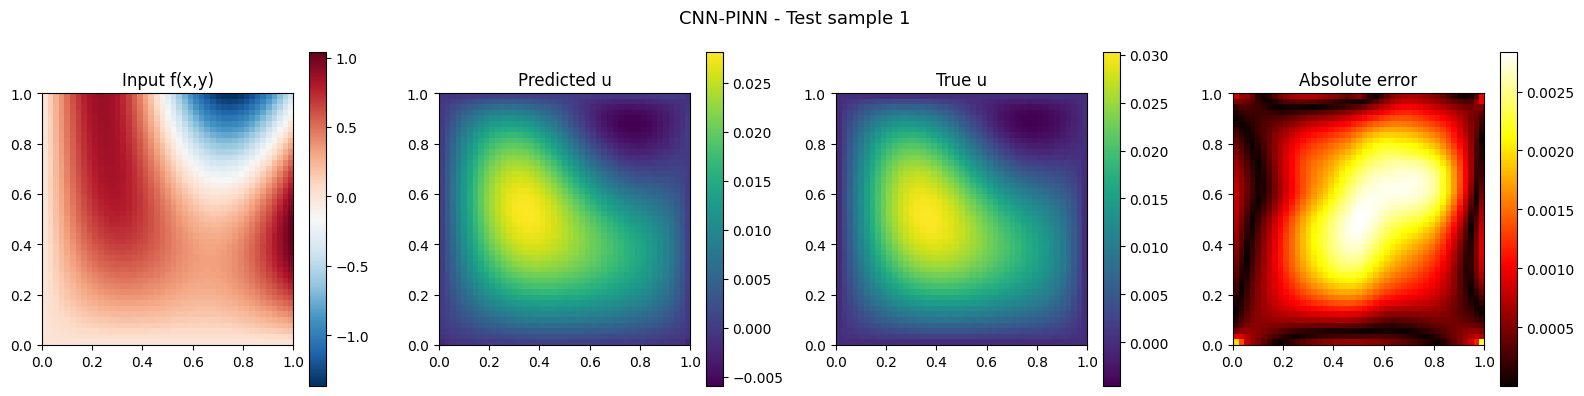

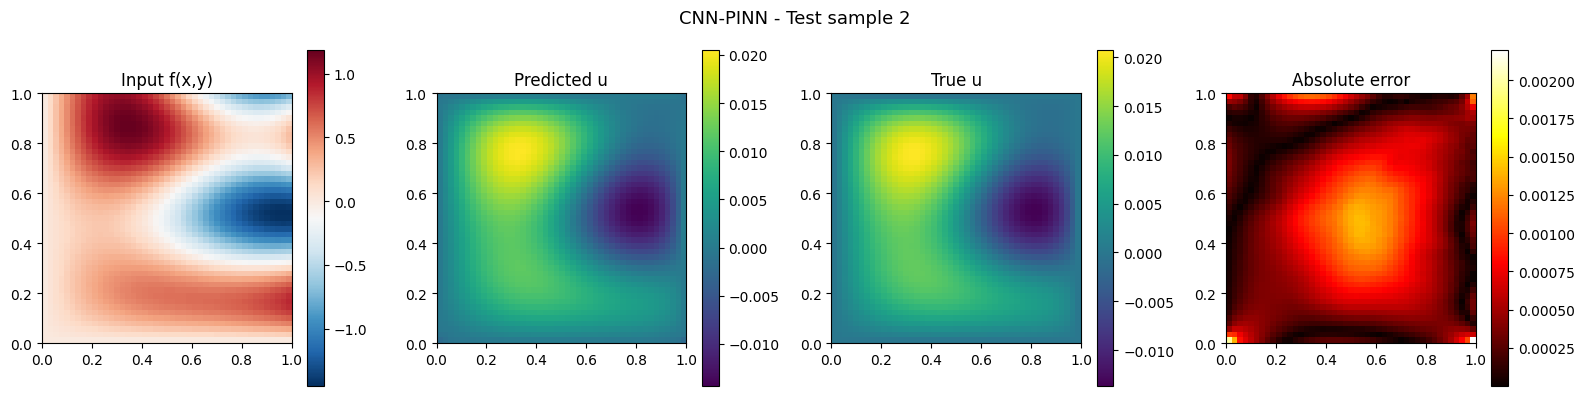

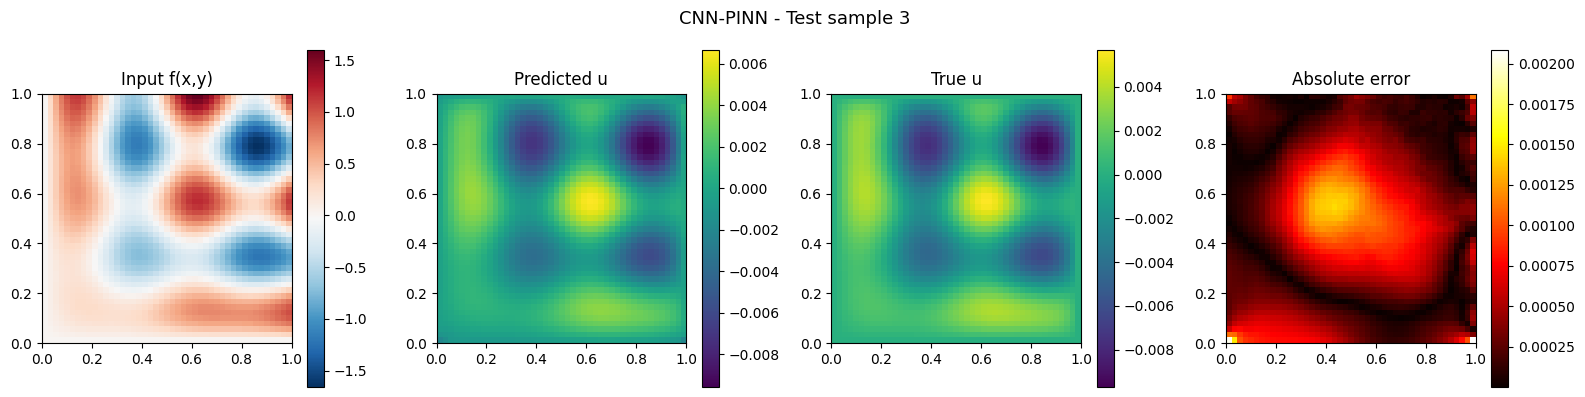

In [348]:
for idx in range(3):
    plot_comparison(pinn_model, X_test, y_test, idx=idx,
                    title=f"CNN-PINN - Test sample {idx+1}",
                    save_path=f"pinn_comparison_{idx}_{RANDOM_SEED}.png")

### BC Violations

Mean BC Violation :
  MLP      : 0.00172
  CNN      : 0.00104
  CNN-PINN : 0.00042


C:\Users\marti\AppData\Local\Temp\ipykernel_26592\3987352772.py:23: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([bc_mlp, bc_cnn, bc_pinn], labels=['MLP', 'CNN', 'CNN-PINN'])


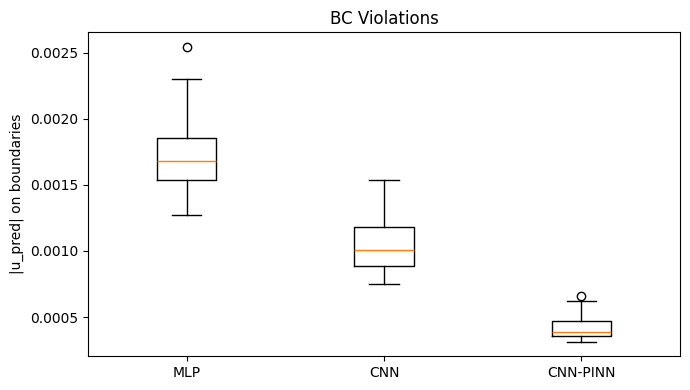

In [349]:
def check_bc_violation(model, X, device, n_samples=50):
    model.eval()
    vals = []
    with torch.no_grad():
        for i in range(n_samples):
            x_t  = torch.FloatTensor(X[i:i+1]).to(device)
            x_t = x_t.squeeze(-1)
            pred = model(x_t).squeeze()   # (45, 45)
            border = torch.cat([pred[0,:], pred[-1,:], pred[:,0], pred[:,-1]])
            vals.append(border.abs().mean().item())
    return np.array(vals)

bc_mlp  = check_bc_violation(best_mlp,   X_test, device)
bc_cnn  = check_bc_violation(best_cnn,   X_test, device)
bc_pinn = check_bc_violation(pinn_model, X_test, device)

print("Mean BC Violation :")
print(f"  MLP      : {bc_mlp.mean():.5f}")
print(f"  CNN      : {bc_cnn.mean():.5f}")
print(f"  CNN-PINN : {bc_pinn.mean():.5f}")

plt.figure(figsize=(7, 4))
plt.boxplot([bc_mlp, bc_cnn, bc_pinn], labels=['MLP', 'CNN', 'CNN-PINN'])
plt.ylabel("|u_pred| on boundaries")
plt.title("BC Violations")
plt.tight_layout()
plt.show()

## 10. Final Comparison — MLP / CNN / CNN-PINN

In [350]:
final_test_mlp = MLP(
    input_size=2025,
    hidden_sizes=best_mlp_params['hidden_sizes'],
    output_size=2025
).to(device)
final_test_cnn = SimpleCNN().to(device)
final_test_pinn = CNNPinn(base_channels=32).to(device)

final_test_mlp.load_state_dict(torch.load("best_MLP.pth", map_location=device))
final_test_cnn.load_state_dict(torch.load("best_SimpleCNN.pth", map_location=device))
final_test_pinn.load_state_dict(torch.load("best_CNNPinn_PINN.pth", map_location=device))

<All keys matched successfully>

In [351]:

source_final_test = np.load("./test_private/source.npy")
u_full_final_test = np.load("./test_private/u_full.npy")


final_test_dataset  = PoissonDataset(source_final_test,  u_full_final_test,  normalize=False)
final_test_loader = DataLoader(final_test_dataset, batch_size=32, shuffle=False)

In [352]:
mlp_final_test_mse, mlp_final_test_mae = evaluate_model(final_test_mlp, final_test_loader, device)
final_bc_mlp  = check_bc_violation(final_test_mlp, source_final_test, device)

cnn_final_test_mse, cnn_final_test_mae = evaluate_model(final_test_cnn, final_test_loader, device)
final_bc_cnn  = check_bc_violation(final_test_cnn, source_final_test, device)

pinn_final_test_mse, pinn_final_test_mae = evaluate_model(final_test_pinn, final_test_loader, device)
final_bc_pinn = check_bc_violation(final_test_pinn, source_final_test, device)

In [353]:
models_info = [
    ('MLP',      final_test_mlp,   mlp_final_test_mse,  mlp_final_test_mae,  final_bc_mlp.mean()),
    ('CNN',      final_test_cnn,   cnn_final_test_mse,  cnn_final_test_mae,  final_bc_cnn.mean()),
    ('CNN-PINN', final_test_pinn, pinn_final_test_mse, pinn_final_test_mae, final_bc_pinn.mean()),
]

header = f"{'Model':<12} {'# Params':>10} {'Test MSE':>12} {'Test MAE':>12} {'BC viol.':>12}"
print(header)
print("-" * len(header))
for name, model, mse, mae, bc in models_info:
    print(f"{name:<12} {count_params(model):>10,} {mse:>12.6f} {mae:>12.6f} {bc:>12.5f}")

Model          # Params     Test MSE     Test MAE     BC viol.
--------------------------------------------------------------
MLP           3,638,249     0.000025     0.003544      0.00238
CNN          15,702,441     0.000005     0.001643      0.00131
CNN-PINN        332,641     0.000000     0.000478      0.00039


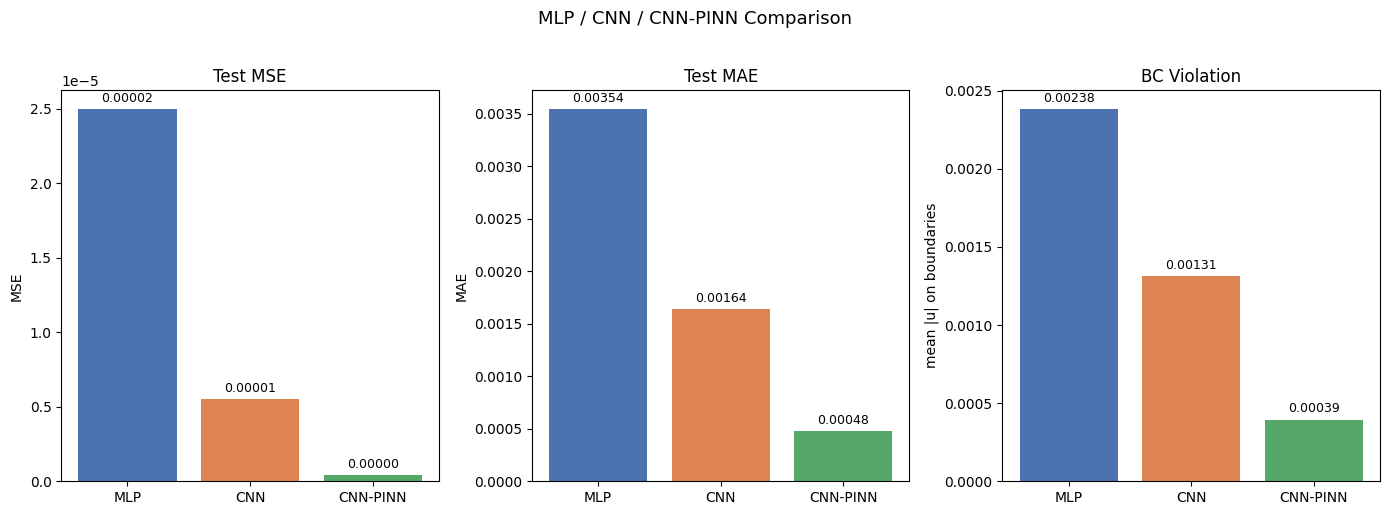

In [354]:
names  = [m[0] for m in models_info]
mses   = [m[2] for m in models_info]
maes   = [m[3] for m in models_info]
bcs    = [m[4] for m in models_info]
colors = ['#4C72B0', '#DD8452', '#55A868']

fig, axes = plt.subplots(1, 3, figsize=(14, 5))
for ax, vals, ylabel, title in zip(
        axes,
        [mses, maes, bcs],
        ['MSE', 'MAE', 'mean |u| on boundaries'],
        ['Test MSE', 'Test MAE', 'BC Violation']):
    bars = ax.bar(names, vals, color=colors)
    ax.bar_label(bars, fmt='%.5f', padding=3, fontsize=9)
    ax.set_title(title); ax.set_ylabel(ylabel)

plt.suptitle('MLP / CNN / CNN-PINN Comparison', fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig(f'final_comparison_{RANDOM_SEED}.png', dpi=120, bbox_inches='tight')
plt.show()

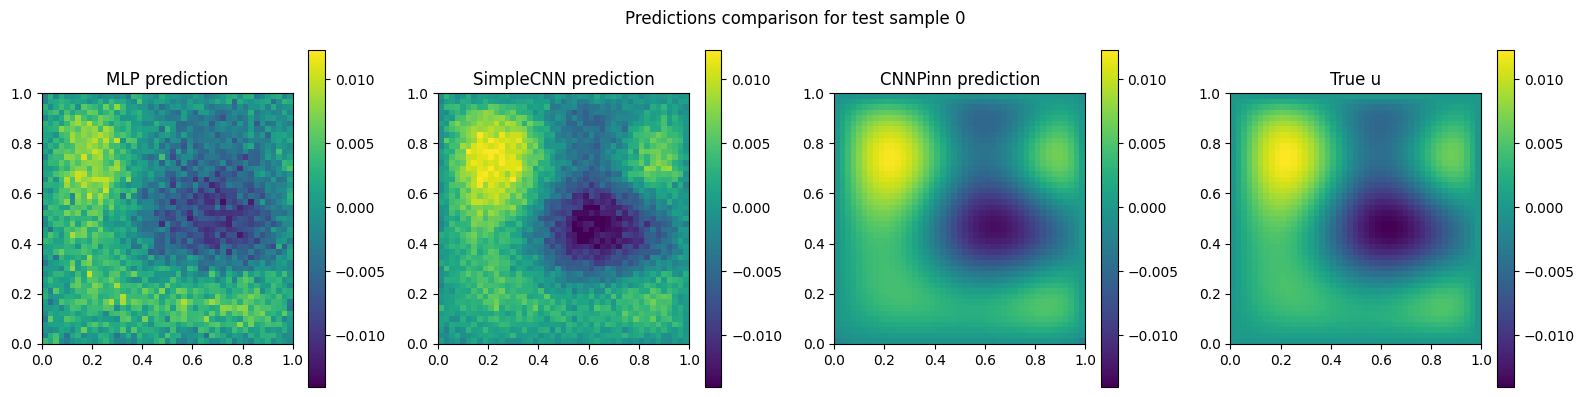

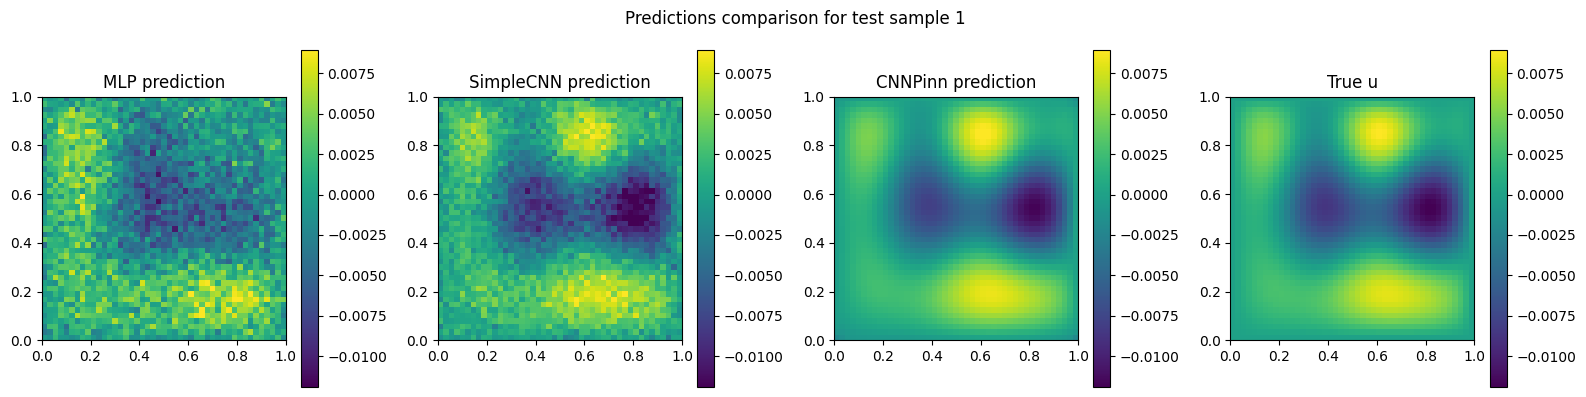

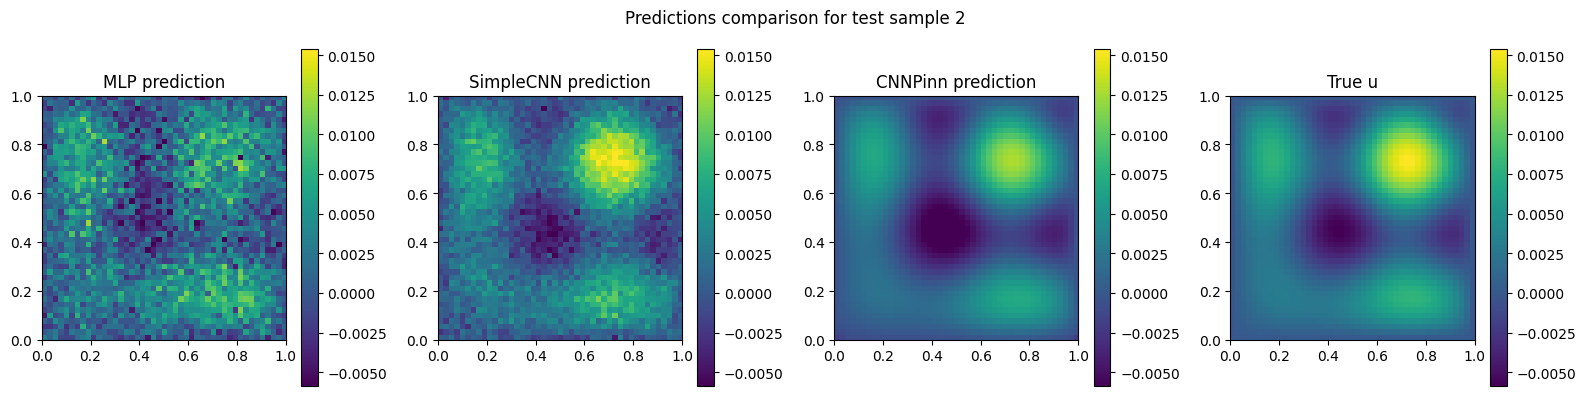

In [355]:
models = [final_test_mlp, final_test_cnn, final_test_pinn]

for idx in range(3):

    true = u_full_final_test[idx].squeeze()
    vmin, vmax = true.min(), true.max()
    plt.figure(figsize=(16, 4))
    plt.suptitle(f"Predictions comparison for test sample {idx}")
    kw = dict(origin='lower', extent=[0,1,0,1], vmin=vmin, vmax=vmax)

    for i, model in enumerate(models):
        with torch.no_grad():
            x_t = torch.FloatTensor(source_final_test[idx:idx+1]).squeeze(dim=-1)
            pred = model(x_t).cpu().numpy().squeeze()

        plt.subplot(1, 4, i + 1)
        plt.imshow(pred, cmap = 'viridis', **kw)
        plt.title(f'{model.__class__.__name__} prediction')
        plt.colorbar()
    
    plt.subplot(1, 4, 4)
    plt.imshow(true, cmap = 'viridis', **kw)
    plt.title('True u')
    plt.colorbar()

    plt.tight_layout()
    plt.savefig(f'final_comparison_sample_{idx}_{RANDOM_SEED}.png', dpi=120, bbox_inches='tight')
    plt.show()
